# Regional labor market data pipeline: walkthrough

This notebook walks through what the pipeline produced and how I checked it. It doesn't re-run the pipeline (that's `python -m qcew_pipeline.run`); it opens the finished database and the evaluation results and shows them.

I wrote the comments in plain language on purpose, so someone who isn't a programmer can still follow what each cell is doing and why.

**What's in here**
1. What the pipeline did, run by run
2. The quality checks and what they found
3. Whether the results are repeatable
4. What happened when I broke the data on purpose
5. A quick look at whether the data is usable for real questions
6. Limits to keep in mind

In [1]:
# Basic setup: libraries, and a way to find the project folder no matter where I open this notebook from.
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)

# Walk up from wherever we are until we find config.toml. That's the project folder.
here = Path.cwd()
project = next(p for p in [here, *here.parents] if (p / "config.toml").exists())

db_path = project / "data" / "qcew_dmv.sqlite"
eval_path = project / "outputs" / "evaluation_results.json"
fig_dir = project / "outputs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect(db_path)
print("Database:", db_path.name, f"({db_path.stat().st_size / 1e6:.1f} MB)")

Database: qcew_dmv.sqlite (1.6 MB)


## 1. What the pipeline did

In [2]:
# Every run of the pipeline leaves one row in pipeline_runs. This is the history, newest first.
runs = pd.read_sql_query(
    "SELECT run_id, started_at, status, rows_inserted, rows_changed, rows_unchanged, "
    "validation_errors AS errors, validation_warnings AS warnings FROM pipeline_runs ORDER BY run_id DESC",
    conn)
runs

,run_id,started_at,status,rows_inserted,rows_changed,rows_unchanged,errors,warnings
0,4,2026-11-23T18:12:46+00:00,failed_validation,NaN,NaN,NaN,1.0,0.0
1,3,2026-11-23T18:12:46+00:00,failed,NaN,NaN,NaN,NaN,NaN
2,2,2026-11-23T18:12:45+00:00,failed,NaN,NaN,NaN,NaN,NaN
3,1,2026-11-23T18:10:23+00:00,success,16232.0,0.0,0.0,0.0,0.0


The rows marked `failed` or `failed_validation` aren't real problems. They're the three failure scenarios I staged on purpose during the evaluation (a year BLS hasn't published, a corrupted download, and a validation failure), which is why the pipeline keeps a log of every run, including the ones that stop.

In [3]:
# Where each file came from. The sha256 column is a fingerprint: if anyone downloads the same file
# from BLS, they should get the same fingerprint. That's how I can prove which file a number came from.
latest_run = pd.read_sql_query("SELECT MAX(run_id) AS r FROM pipeline_runs WHERE status = 'success'", conn)["r"][0]
pd.read_sql_query(
    "SELECT year, download_status, size_bytes / 1e6 AS size_mb, rows_scanned, rows_kept, substr(sha256, 1, 16) AS sha256_start "
    "FROM source_files WHERE run_id = ? ORDER BY year", conn, params=[latest_run])

,year,download_status,size_mb,rows_scanned,rows_kept,sha256_start


In [4]:
# How big is the finished table, and what does it cover?
pd.read_sql_query(
    "SELECT year, COUNT(*) AS rows, COUNT(DISTINCT area_fips) AS areas, COUNT(DISTINCT industry_code) AS industries "
    "FROM qcew_annual GROUP BY year ORDER BY year", conn)

,year,rows,areas,industries
0,2020,3222,164,21
1,2021,3227,164,21
2,2022,3250,164,21
3,2023,3278,164,21
4,2024,3255,164,21


Each year starts with about 3.6 million rows nationally and ends up as a few thousand rows for DC, Maryland and Virginia, which is exactly the point of the filter step.

## 2. The quality checks

In [5]:
# The 16 checks from the latest successful run. 'error' checks would have stopped the load.
# 'warn' checks get recorded for a person to look at. 'info' is just a fact worth writing down.
checks = pd.read_sql_query(
    "SELECT check_name, level, CASE passed WHEN 1 THEN 'pass' ELSE 'FAIL' END AS result, failed_count, detail "
    "FROM validation_results WHERE run_id = ? ORDER BY CASE level WHEN 'error' THEN 0 WHEN 'warn' THEN 1 ELSE 2 END, check_name",
    conn, params=[latest_run])
checks

,check_name,level,result,failed_count,detail


In [6]:
# The one thing I wanted to be most careful about: values BLS hides for confidentiality.
# They come in the raw file as zeros, but they aren't zeros, so I store them as NULL and flag them.
supp = pd.read_sql_query(
    "SELECT year, COUNT(*) AS rows, SUM(is_suppressed) AS suppressed, "
    "ROUND(100.0 * SUM(is_suppressed) / COUNT(*), 1) AS pct_suppressed, "
    "SUM(CASE WHEN is_suppressed = 1 AND employment IS NOT NULL THEN 1 ELSE 0 END) AS suppressed_with_a_number "
    "FROM qcew_annual GROUP BY year ORDER BY year", conn)
supp

,year,rows,suppressed,pct_suppressed,suppressed_with_a_number
0,2020,3222,789,24.5,0
1,2021,3227,792,24.5,0
2,2022,3250,785,24.2,0
3,2023,3278,814,24.8,0
4,2024,3255,904,27.8,0


The last column should be zero in every year. It is, so no hidden value was turned into a fake zero.

## 3. Is it repeatable?

In [7]:
# These numbers come from evaluation/run_evaluation.py, which I ran against the real BLS files.
ev = json.loads(eval_path.read_text())

rows = []
for label, key in [("Cold run (downloads the files)", "cold_run"),
                   ("Repeat run, same database", "repeat_run_same_database"),
                   ("Rebuild database from scratch", "rebuild_from_scratch")]:
    r = ev[key]
    rows.append({
        "scenario": label,
        "status": r["status"],
        "total_seconds": r["timings_seconds"]["total"],
        "collect_s": r["timings_seconds"].get("collect"),
        "transform_s": r["timings_seconds"].get("transform"),
        "validate_s": r["timings_seconds"].get("validate"),
        "load_s": r["timings_seconds"].get("load"),
        "rows_inserted": r["load"]["inserted"],
        "rows_changed": r["load"]["changed"],
        "same_data_as_cold_run": r.get("same_data_as_cold_run", "-"),
    })
repro = pd.DataFrame(rows)
repro

,scenario,status,total_seconds,collect_s,transform_s,validate_s,load_s,rows_inserted,rows_changed,same_data_as_cold_run
0,Cold run (downloads the files),success,204.01,107.51,95.25,0.23,0.86,16232,0,-
1,"Repeat run, same database",success,149.04,0.77,141.14,0.21,6.87,0,0,True
2,Rebuild database from scratch,success,139.38,0.96,137.11,0.21,0.99,16232,0,True


How to read that table:

* **Repeat run:** the database already had everything, so nothing should be inserted or changed. If rows were added, my upsert would be creating duplicates.
* **Rebuild:** I deleted the database and loaded again from the same files. If the data fingerprint matches the cold run, the pipeline rebuilds exactly the same dataset.
* The timing difference between the cold run and the others is mostly download time.

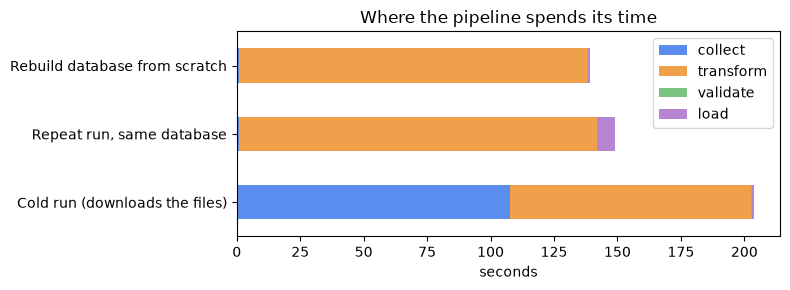

In [8]:
# Quick picture of where the time goes in each scenario.
stages = ["collect_s", "transform_s", "validate_s", "load_s"]
ax = repro.set_index("scenario")[stages].rename(columns=lambda c: c.replace("_s", "")).plot(kind="barh", stacked=True, figsize=(8, 3), color=["#5b8def", "#f0a04b", "#7bc47f", "#b784d1"])
ax.set_xlabel("seconds")
ax.set_ylabel("")
ax.set_title("Where the pipeline spends its time")
plt.tight_layout()
plt.savefig(fig_dir / "pipeline_timing.png", dpi=160)
plt.show()

## 4. What happens when something is wrong

In [9]:
# I took the real data, broke one thing at a time, and ran the checks.
# 'caught' means the check I wrote for that problem noticed it.
faults = pd.DataFrame(ev["fault_injection"]["faults"])
faults["caught_by_expected_check"] = faults["caught_by_expected_check"].map({True: "yes", False: "NO"})
print(f"{ev['fault_injection']['caught']} of {ev['fault_injection']['total']} injected faults were caught.")
print("Checks that failed on the unmodified data:", ev["fault_injection"]["clean_data_failed_checks"] or "none")
faults[["injected_fault", "expected_check", "caught_by_expected_check"]]

11 of 11 injected faults were caught.
Checks that failed on the unmodified data: none


,injected_fault,expected_check,caught_by_expected_check
0,Duplicate row,no_duplicate_keys,yes
1,Area code that doesn't exist,valid_area_codes,yes
2,Industry code that doesn't exist,valid_industry_codes,yes
3,Missing key field,required_fields_not_null,yes
4,Suppressed value stored as zero,suppressed_values_are_null_not_zero,yes
5,Negative employment,no_negative_measures,yes
6,A whole year missing,all_years_present_with_enough_rows,yes
7,One county missing in one year,same_counties_in_every_year,yes
8,County total tripled,county_totals_agree_with_state_total,yes
9,One sector inflated above county total,sector_sum_not_above_county_total,yes


In [10]:
# These are bigger things going wrong: a year BLS hasn't published, a corrupted download,
# and data that fails validation. The key question is whether the database was left alone.
pd.DataFrame(ev["failure_scenarios"])[
    ["scenario", "expected_status", "actual_status", "data_unchanged"]]

,scenario,expected_status,actual_status,data_unchanged
0,Year that BLS hasn't published (2099),failed,failed,True
1,Corrupted zip file,failed,failed,True
2,Validation error blocks the load,failed_validation,failed_validation,True


## 5. Can the data answer real questions?

This isn't meant to be a labor market analysis (the capstone is about the pipeline, not the economy). These are just two quick examples to show the database is usable and the numbers behave sensibly.

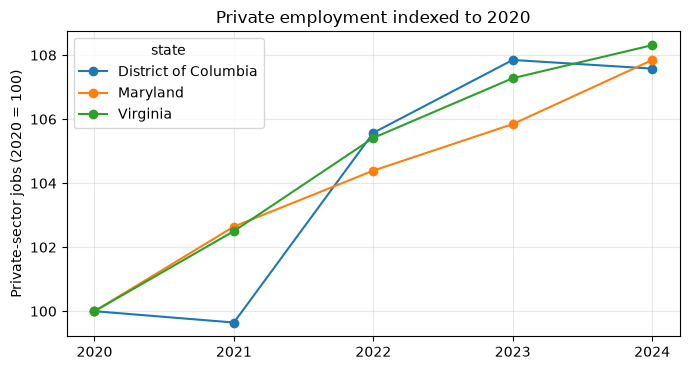

state,District of Columbia,Maryland,Virginia
year,,,
2020,487254,1956288,2907491
2021,485530,2008032,2980226
2022,514413,2042218,3064937
2023,525505,2070645,3119153
2024,524190,2109770,3149137


In [11]:
# Private-sector jobs by state, indexed so 2020 = 100. Summing counties is fine here because
# the state-reconciliation check already showed county totals agree with BLS's state totals.
by_state = pd.read_sql_query(
    "SELECT year, state_fips, SUM(employment) AS jobs FROM v_county_totals GROUP BY year, state_fips", conn)
by_state["state"] = by_state["state_fips"].map({"11": "District of Columbia", "24": "Maryland", "51": "Virginia"})
wide = by_state.pivot(index="year", columns="state", values="jobs")
index = wide / wide.iloc[0] * 100

ax = index.plot(marker="o", figsize=(7, 3.8))
ax.set_ylabel("Private-sector jobs (2020 = 100)")
ax.set_xlabel("")
ax.set_xticks(index.index)
ax.set_title("Private employment indexed to 2020")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(fig_dir / "employment_index.png", dpi=160)
plt.show()
wide.round(0).astype(int)

In [12]:
# The ten counties with the highest average weekly wage in 2024. I skip any county where BLS
# suppressed the number rather than treating it as missing or zero.
top = pd.read_sql_query(
    "SELECT area_title, employment, avg_weekly_wage FROM v_county_totals "
    "WHERE year = 2024 AND is_suppressed = 0 ORDER BY avg_weekly_wage DESC LIMIT 10", conn)
top

,area_title,employment,avg_weekly_wage
0,"Goochland County, Virginia",17055.0,2393.0
1,"Arlington County, Virginia",140502.0,2361.0
2,"District of Columbia, not unknown",524190.0,2269.0
3,"Fairfax County, Virginia",549996.0,2250.0
4,"Surry County, Virginia",1657.0,2204.0
5,"Montgomery County, Maryland",367114.0,1724.0
6,"Howard County, Maryland",154553.0,1678.0
7,"Alexandria City, Virginia",64331.0,1670.0
8,"Loudoun County, Virginia",166777.0,1631.0
9,"Richmond City, Virginia",124895.0,1604.0


## 6. Things to keep in mind

* **One source.** Everything comes from the BLS QCEW annual files. I haven't merged in another source, so this shows pipeline engineering on one source, not data integration across sources.
* **Private sector only.** Government jobs are left out on purpose.
* **Suppression.** Some county-sector values are hidden by BLS. The pipeline preserves that as NULL instead of guessing, which means sector-level sums for small counties are lower bounds.
* **Jobs, not people.** QCEW counts jobs at employers located in the county. It says nothing about where workers live or who they are.
* **One machine.** The timings are from a single Windows laptop on one home connection. They show relative differences, not benchmarks.

In [13]:
conn.close()